In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
import warnings

from sklearn.metrics import accuracy_score, classification_report
from sklearn.preprocessing import LabelEncoder, StandardScaler,OneHotEncoder,OrdinalEncoder
from sklearn.metrics import roc_curve, roc_auc_score

from sklearn.compose import ColumnTransformer
from sklearn.metrics import (mean_absolute_error,mean_squared_error,r2_score,accuracy_score,classification_report,
    confusion_matrix,roc_auc_score,f1_score,mean_absolute_percentage_error)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier,ExtraTreesClassifier
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import f1_score, average_precision_score
from sklearn.linear_model import LogisticRegression, LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import RandomizedSearchCV
from xgboost import XGBRegressor
from sklearn.impute import SimpleImputer
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.model_selection import train_test_split, cross_val_score, KFold, StratifiedKFold
RANDOM_STATE = 42

C:\Users\rahul\anaconda3\lib\site-packages\scipy\__init__.py:138: UserWarning: A NumPy version >=1.16.5 and <1.23.0 is required for this version of SciPy (detected version 1.24.4)
  warnings.warn(f"A NumPy version >={np_minversion} and <{np_maxversion} is required for this version of "


# 1) Data Loading

In [2]:
df=pd.read_csv('festival_sales_consumer_behavior.csv')

In [3]:
print("We have {} Rows and {} Columns in our data".format(df.shape[0], df.shape[1]))

We have 18000 Rows and 27 Columns in our data


In [4]:
df.head(5)

,customer_id,sale_event,platform,age,gender,city_tier,state,income_bracket,device_type,membership_tier,...,social_media_influence_score,cart_abandonment_history,previous_festival_purchase,delivery_speed_expectation,payment_method,converted,items_purchased,amount_spent,return_requested,purchase_timestamp
0,CUST100000,Amazon Great Indian Festival,Myntra,33,Female,Tier 2,Punjab,7-15L,Mobile,NaN,...,4.5,1,0,1-2 days,UPI,1,4,205673.0,0,2025-10-01 07:28:00
1,CUST100001,Meesho Mega Blockbuster Sale,Meesho,21,Female,Tier 2,Uttar Pradesh,15L+,Mobile,NaN,...,NaN,1,0,No preference,UPI,0,0,0.0,0,NaN
2,CUST100002,Meesho Mega Blockbuster Sale,Flipkart,37,Male,Tier 3,Uttarakhand,<3L,Mobile,NaN,...,10.0,1,0,1-2 days,EMI,0,0,0.0,0,NaN
3,CUST100003,Flipkart Big Billion Days,Flipkart,39,Female,Tier 1,West Bengal,7-15L,Mobile,NaN,...,3.4,0,0,1-2 days,EMI,0,0,0.0,0,NaN
4,CUST100004,Meesho Mega Blockbuster Sale,Myntra,18,Male,Tier 3,Uttarakhand,7-15L,Mobile,NaN,...,5.7,0,0,No preference,COD,1,1,710.0,0,2025-10-05 09:38:00


In [5]:
df.columns

Index(['customer_id', 'sale_event', 'platform', 'age', 'gender', 'city_tier',
       'state', 'income_bracket', 'device_type', 'membership_tier',
       'category_browsed', 'price_original', 'discount_percent_offered',
       'price_final', 'days_before_sale_wishlist_added',
       'app_session_count_pre_sale', 'notification_opt_in',
       'social_media_influence_score', 'cart_abandonment_history',
       'previous_festival_purchase', 'delivery_speed_expectation',
       'payment_method', 'converted', 'items_purchased', 'amount_spent',
       'return_requested', 'purchase_timestamp'],
      dtype='object')

In [6]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
customer_id,18000,18000,CUST100000,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sale_event,18000,4,Amazon Great Indian Festival,5494,NaN,NaN,NaN,NaN,NaN,NaN,NaN
platform,18000,5,Flipkart,6172,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,18000.0,NaN,NaN,NaN,30.824056,8.397415,18.0,24.0,30.0,36.0,65.0
gender,18000,3,Male,10059,NaN,NaN,NaN,NaN,NaN,NaN,NaN
city_tier,18000,3,Tier 1,6807,NaN,NaN,NaN,NaN,NaN,NaN,NaN
state,18000,18,Telangana,1182,NaN,NaN,NaN,NaN,NaN,NaN,NaN
income_bracket,18000,4,3-7L,6470,NaN,NaN,NaN,NaN,NaN,NaN,NaN
device_type,18000,3,Mobile,13964,NaN,NaN,NaN,NaN,NaN,NaN,NaN
membership_tier,4566,2,Prime,2626,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# 2) Data Cleaning

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18000 entries, 0 to 17999
Data columns (total 27 columns):
 #   Column                           Non-Null Count  Dtype  
---  ------                           --------------  -----  
 0   customer_id                      18000 non-null  object 
 1   sale_event                       18000 non-null  object 
 2   platform                         18000 non-null  object 
 3   age                              18000 non-null  int64  
 4   gender                           18000 non-null  object 
 5   city_tier                        18000 non-null  object 
 6   state                            18000 non-null  object 
 7   income_bracket                   18000 non-null  object 
 8   device_type                      18000 non-null  object 
 9   membership_tier                  4566 non-null   object 
 10  category_browsed                 18000 non-null  object 
 11  price_original                   18000 non-null  float64
 12  discount_percent_o

In [8]:
# check the missing values
df.isnull().sum()

customer_id                            0
sale_event                             0
platform                               0
age                                    0
gender                                 0
city_tier                              0
state                                  0
income_bracket                         0
device_type                            0
membership_tier                    13434
category_browsed                       0
price_original                         0
discount_percent_offered               0
price_final                            0
days_before_sale_wishlist_added        0
app_session_count_pre_sale             0
notification_opt_in                    0
social_media_influence_score         270
cart_abandonment_history               0
previous_festival_purchase             0
delivery_speed_expectation           180
payment_method                         0
converted                              0
items_purchased                        0
amount_spent    

In [9]:
missing=df.isnull().sum()
missing=missing[missing>0]
missing_df=pd.DataFrame({'count':missing,'pct':(missing/len(df)*100).round(2)}).sort_values('count',ascending=False)

missing_df

,count,pct
membership_tier,13434,74.63
purchase_timestamp,9812,54.51
social_media_influence_score,270,1.50
delivery_speed_expectation,180,1.00


In [10]:
df['membership_tier']=df['membership_tier'].fillna('No Membership')
df['social_media_influence_score']=df['social_media_influence_score'].fillna(df['social_media_influence_score'].median())
df['delivery_speed_expectation']=df['delivery_speed_expectation'].fillna('Not Specified')

assert df.drop(columns='purchase_timestamp').isnull().sum().sum()==0

In [11]:
# check the duplicate values
df.duplicated().sum()

0

# 3) Exploratory Data Analysis

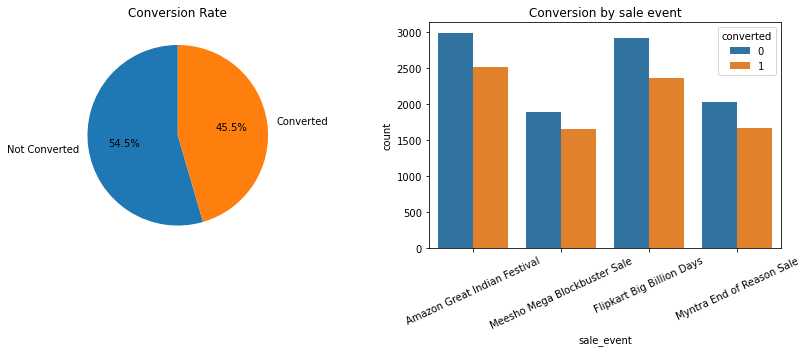

In [12]:
counts=df['converted'].value_counts()

fig,ax=plt.subplots(1,2,figsize=(12,5))

ax[0].pie(counts,labels=['Not Converted', 'Converted'],autopct='%1.1f%%',startangle=90)
ax[0].set_title('Conversion Rate')

sns.countplot(data=df,x='sale_event',hue='converted',ax=ax[1])
ax[1].set_title('Conversion by sale event')
ax[1].tick_params(axis='x',rotation=25)

plt.tight_layout()
plt.show()

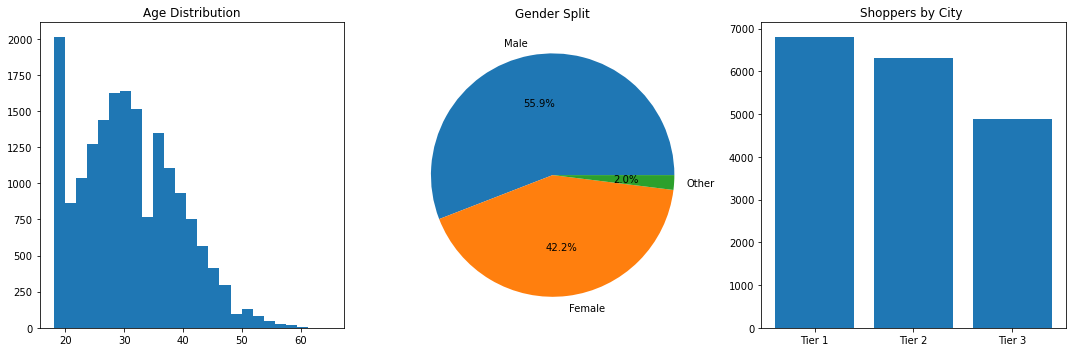

In [13]:
fig,ax=plt.subplots(1,3,figsize=(15,5))

ax[0].hist(df['age'].dropna(),bins=25)
ax[0].set_title('Age Distribution')

g=df['gender'].value_counts()
ax[1].pie(g.to_numpy(),labels=g.index.to_numpy(),autopct='%1.1f%%')
ax[1].set_title('Gender Split')

city=df['city_tier'].value_counts().reindex(['Tier 1', 'Tier 2', 'Tier 3'])
ax[2].bar(city.index.to_numpy(),city.to_numpy())
ax[2].set_title('Shoppers by City ')

plt.tight_layout()
plt.show()

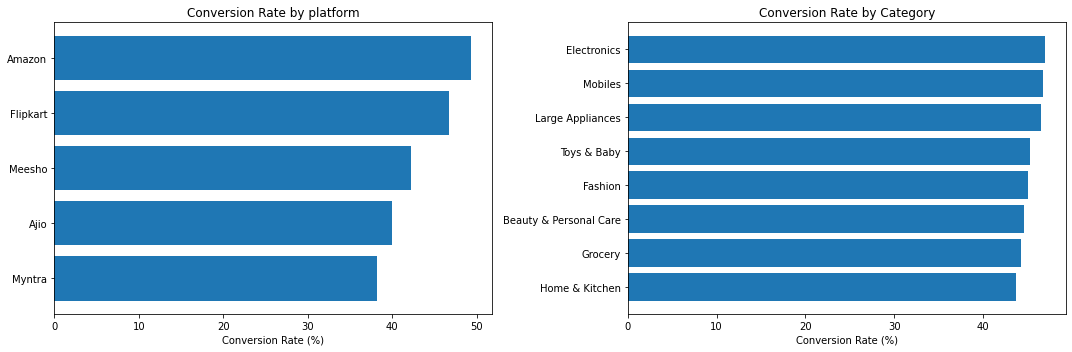

In [14]:
fig, ax=plt.subplots(1,2,figsize=(15,5))

p=df.groupby('platform')['converted'].mean().mul(100).sort_values()
ax[0].barh(p.index,p.values)
ax[0].set_title('Conversion Rate by platform')
ax[0].set_xlabel('Conversion Rate (%)')

c=df.groupby('category_browsed')['converted'].mean().mul(100).sort_values()
ax[1].barh(c.index,c.values)
ax[1].set_title('Conversion Rate by Category')
ax[1].set_xlabel('Conversion Rate (%)')

plt.tight_layout()
plt.show()

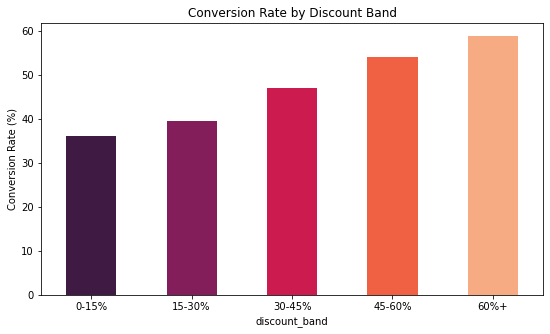

In [15]:
df['discount_band']=pd.cut(df['discount_percent_offered'],bins=[0,15,30,45,60,100],
                          labels=['0-15%','15-30%','30-45%','45-60%','60%+'])
discount_conversion=df.groupby('discount_band',observed=True)['converted'].mean()*100

plt.figure(figsize=(9,5))
discount_conversion.plot.bar(color=sns.color_palette('rocket',len(discount_conversion)))
plt.ylabel('Conversion Rate (%)')
plt.title('Conversion Rate by Discount Band')
plt.xticks(rotation=0)
plt.show()

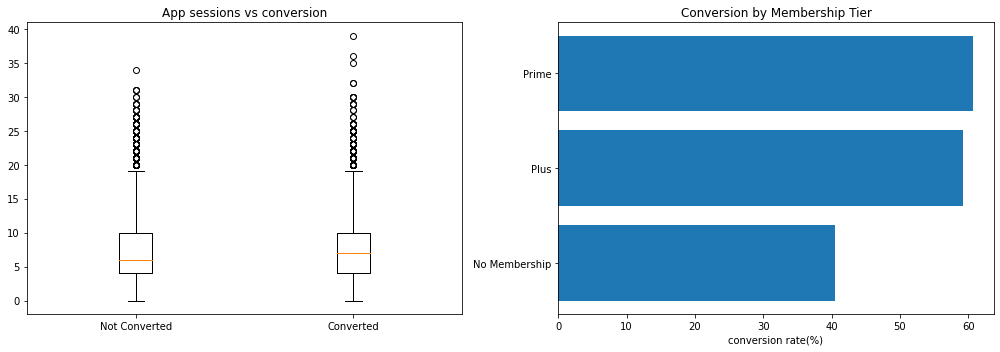

In [16]:
fig,ax=plt.subplots(1,2,figsize=(14,5))

ax[0].boxplot([df.loc[df['converted']==0,'app_session_count_pre_sale'],
               df.loc[df['converted']==1,'app_session_count_pre_sale']])

ax[0].set_xticks([1,2])
ax[0].set_xticklabels(['Not Converted', 'Converted'])
ax[0].set_title('App sessions vs conversion')

m=df.groupby('membership_tier')['converted'].mean().mul(100).sort_values()
ax[1].barh(m.index,m.values)
ax[1].set_title('Conversion by Membership Tier')
ax[1].set_xlabel('conversion rate(%)')

plt.tight_layout()
plt.show() 

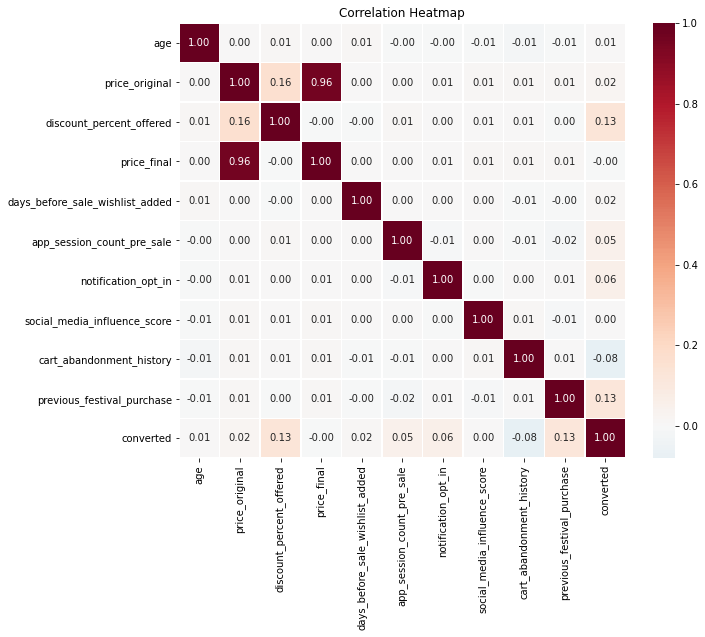

In [17]:
numerical_columns = ['age', 'price_original', 'discount_percent_offered', 'price_final',
                     'days_before_sale_wishlist_added', 'app_session_count_pre_sale','notification_opt_in', 'social_media_influence_score',
                     'cart_abandonment_history', 'previous_festival_purchase', 'converted']
plt.figure(figsize=(10, 8))
sns.heatmap(df[numerical_columns].corr(), annot=True, fmt='.2f', cmap='RdBu_r', center=0,linewidths=0.5)

plt.title('Correlation Heatmap')
plt.show()

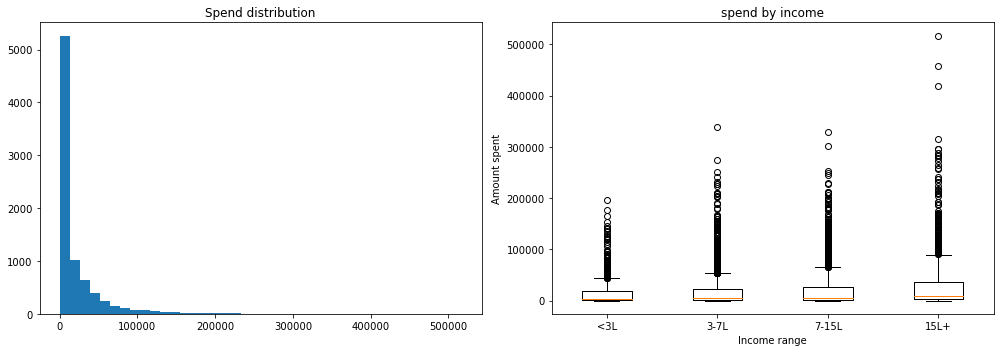

count      8188.000000
mean      20080.443087
std       35237.190903
min          63.000000
25%        1550.000000
50%        5133.500000
75%       24274.500000
max      516789.000000
Name: amount_spent, dtype: float64


In [18]:
buyers=df[df['converted']==1]

fig,ax=plt.subplots(1,2,figsize=(14,5))

ax[0].hist(buyers['amount_spent'],bins=40)
ax[0].set_title('Spend distribution')

income=[buyers.loc[buyers['income_bracket'] == x, 'amount_spent']
                for x in ['<3L', '3-7L', '7-15L', '15L+']]

ax[1].boxplot(income,labels=['<3L', '3-7L', '7-15L', '15L+'])
ax[1].set_title('spend by income')
ax[1].set_xlabel('Income range')
ax[1].set_ylabel('Amount spent')

plt.tight_layout()
plt.show()

print(buyers['amount_spent'].describe())

# 4)Feature Engineering

In [19]:
target='converted'

exclude=['customer_id', 'items_purchased', 'amount_spent','return_requested', 'purchase_timestamp', 'discount_band']

features=[c for c in df.columns if c not in exclude + [target]]

print(f"Model features({len(features)}):")
print(features)

Model features(21):
['sale_event', 'platform', 'age', 'gender', 'city_tier', 'state', 'income_bracket', 'device_type', 'membership_tier', 'category_browsed', 'price_original', 'discount_percent_offered', 'price_final', 'days_before_sale_wishlist_added', 'app_session_count_pre_sale', 'notification_opt_in', 'social_media_influence_score', 'cart_abandonment_history', 'previous_festival_purchase', 'delivery_speed_expectation', 'payment_method']


In [20]:
categorical_features = ['sale_event', 'platform', 'gender', 'city_tier', 'state',
                        'income_bracket', 'device_type', 'membership_tier',
                        'category_browsed', 'delivery_speed_expectation', 'payment_method']

numeric_features = [c for c in features if c not in categorical_features]

print("Categorical:", categorical_features)
print("Numeric:", numeric_features)

Categorical: ['sale_event', 'platform', 'gender', 'city_tier', 'state', 'income_bracket', 'device_type', 'membership_tier', 'category_browsed', 'delivery_speed_expectation', 'payment_method']
Numeric: ['age', 'price_original', 'discount_percent_offered', 'price_final', 'days_before_sale_wishlist_added', 'app_session_count_pre_sale', 'notification_opt_in', 'social_media_influence_score', 'cart_abandonment_history', 'previous_festival_purchase']


In [21]:
OneHotEncoder(handle_unknown='ignore')

OneHotEncoder(handle_unknown='ignore')

In [22]:
preprocessor = ColumnTransformer([('num', StandardScaler(), numeric_features),
    ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)])

# 5) Train Test Split

In [23]:
X = df[features]
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print("Train:", X_train.shape, "Test:", X_test.shape)
print("Conversion rate:", round(y_train.mean(), 3), round(y_test.mean(), 3))

Train: (14400, 21) Test: (3600, 21)
Conversion rate: 0.455 0.455


In [24]:
model = Pipeline([('prep', preprocessor),('clf', LogisticRegression(max_iter=1000, random_state=42))])

model.fit(X_train, y_train)
pred = model.predict(X_test)
prob = model.predict_proba(X_test)[:, 1]

print("Logistic Regression")
print("Accuracy:", round(accuracy_score(y_test, pred), 4))
print("ROC-AUC :", round(roc_auc_score(y_test, prob), 4))

Logistic Regression
Accuracy: 0.6219
ROC-AUC : 0.6484


In [25]:
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=200, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42),
    'XGBoost': XGBClassifier(eval_metric='logloss', random_state=42)}

results, fitted_models = [], {}

for name, clf in models.items():
    pipe = Pipeline([('prep', preprocessor), ('clf', clf)])
    pipe.fit(X_train, y_train)

    pred = pipe.predict(X_test)
    prob = pipe.predict_proba(X_test)[:, 1]

    results.append({'Model': name,'Accuracy': accuracy_score(y_test, pred),'Precision': precision_score(y_test, pred),
        'Recall': recall_score(y_test, pred),'F1': f1_score(y_test, pred),'ROC-AUC': roc_auc_score(y_test, prob)})
    fitted_models[name] = pipe

results_df = pd.DataFrame(results).sort_values('ROC-AUC', ascending=False).reset_index(drop=True)
results_df

,Model,Accuracy,Precision,Recall,F1,ROC-AUC
0,Logistic Regression,0.621944,0.605645,0.484737,0.538488,0.648401
1,Gradient Boosting,0.619722,0.608032,0.462149,0.525147,0.647268
2,Random Forest,0.603333,0.585227,0.440171,0.502439,0.626177
3,XGBoost,0.588611,0.555477,0.479853,0.514903,0.600929


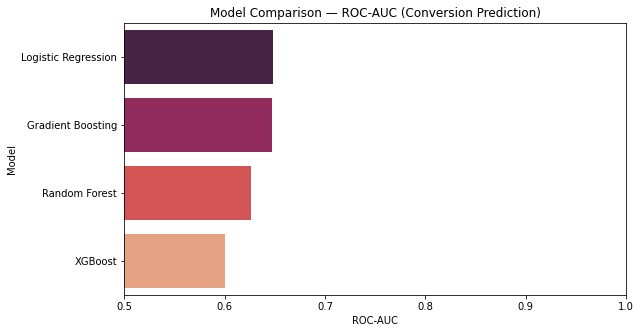

In [26]:
plt.figure(figsize=(9, 5))
sns.barplot(data=results_df, x='ROC-AUC', y='Model', palette='rocket')
plt.title('Model Comparison — ROC-AUC (Conversion Prediction)')
plt.xlim(0.5, 1.0)

plt.show()

In [27]:
params = {
    'clf__n_estimators': [150, 250, 350],
    'clf__max_depth': [3, 4, 5, 6],
    'clf__learning_rate': [0.03, 0.05, 0.1],
    'clf__subsample': [0.7, 0.85, 1.0],
    'clf__colsample_bytree': [0.7, 0.85, 1.0]
}

xgb_pipe = Pipeline([('prep', preprocessor),('clf', XGBClassifier(eval_metric='logloss', random_state=42))])

search = RandomizedSearchCV(xgb_pipe, params, n_iter=15, scoring='roc_auc',cv=3, random_state=42, n_jobs=-1)

search.fit(X_train, y_train)

print("Best parameters:", search.best_params_)
print("Best CV ROC-AUC:", round(search.best_score_, 4))

best_model = search.best_estimator_

Best parameters: {'clf__subsample': 0.7, 'clf__n_estimators': 150, 'clf__max_depth': 3, 'clf__learning_rate': 0.03, 'clf__colsample_bytree': 0.85}
Best CV ROC-AUC: 0.655


In [28]:
final_pred = best_model.predict(X_test)
final_prob = best_model.predict_proba(X_test)[:, 1]

print(classification_report(y_test, final_pred,target_names=['Not Converted', 'Converted']))

print("Test ROC-AUC:", round(roc_auc_score(y_test, final_prob), 4))

               precision    recall  f1-score   support

Not Converted       0.62      0.77      0.69      1962
    Converted       0.61      0.45      0.52      1638

     accuracy                           0.62      3600
    macro avg       0.62      0.61      0.60      3600
 weighted avg       0.62      0.62      0.61      3600

Test ROC-AUC: 0.6508


<ipython-input-29-d87476baabef>:8: MatplotlibDeprecationWarning: Passing the minor parameter of set_ticks() positionally is deprecated since Matplotlib 3.2; the parameter will become keyword-only two minor releases later.
  ax[0].set_xticks([0, 1], ['Not Converted', 'Converted'])
<ipython-input-29-d87476baabef>:9: MatplotlibDeprecationWarning: Passing the minor parameter of set_ticks() positionally is deprecated since Matplotlib 3.2; the parameter will become keyword-only two minor releases later.
  ax[0].set_yticks([0, 1], ['Not Converted', 'Converted'])


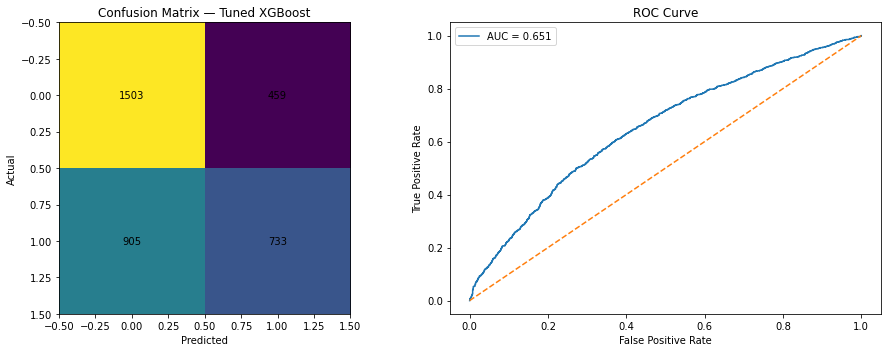

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

cm = confusion_matrix(y_test, final_pred)
ax[0].imshow(cm)
ax[0].set_title('Confusion Matrix — Tuned XGBoost')
ax[0].set_xlabel('Predicted')
ax[0].set_ylabel('Actual')
ax[0].set_xticks([0, 1], ['Not Converted', 'Converted'])
ax[0].set_yticks([0, 1], ['Not Converted', 'Converted'])

for i in range(2):
    for j in range(2):
        ax[0].text(j, i, cm[i, j], ha='center', va='center')

fpr, tpr, _ = roc_curve(y_test, final_prob)
auc = roc_auc_score(y_test, final_prob)

ax[1].plot(fpr, tpr, label=f'AUC = {auc:.3f}')
ax[1].plot([0, 1], [0, 1], '--')
ax[1].set(xlabel='False Positive Rate', ylabel='True Positive Rate',title='ROC Curve')
ax[1].legend()

plt.tight_layout()
plt.show()